## 0. Chargement des données

In [1]:
import sys
sys.path.append("..")  # pour importer le dossier sources/, situé à la racine du dépôt (chemin relatif : marche sur toutes les machines)

In [2]:
# Chargement des 8 sessions : téléchargées une seule fois, puis relues depuis data/raw/
import pandas as pd

from sources.chargement_data import charger_parcoursup, charger_poursuite, charger_ips,telecharger, DATASETS
from sources.cleaning_data import preparer_base, harmoniser_ips, preparer_poursuite, base_selective
from sources.jointures import joindre_ips, panel_academies
from sources.indicateurs import (taux_poursuite, part_poursuite_autre_academie_idf,
                                 part_admis_meme_academie, boursiers_admis_et_candidats,
                                 ajouter_tranche_ips, part_bac_admis, bac_pro_bacheliers_et_admis,part_filles_globale, parts_mentions)
from sources.graphiques import courbes, barres, nuage, tableau_comp_1, diagramme_baton_normalise

dfs = {annee: charger_parcoursup(annee) for annee in DATASETS}

Préparation de la base : identifiant de formation suivi dans le temps (`code`), sélectivité (`selective`) et filière (`filiere`) harmonisées, puis empilement des sessions. Les choix sont justifiés dans `notebooks/exploration.ipynb`.

In [3]:

base = preparer_base(dfs)

print(base.shape)
print("sélectivité manquante :", base["selective"].isna().sum())
base.groupby("session").size()

(104274, 133)
sélectivité manquante : 634


session
2018    10697
2019    11577
2020    12760
2021    13396
2022    13644
2023    13869
2024    14079
2025    14252
dtype: int64

##  1 . Enrichissement : l'indice de position sociale (IPS) des lycées

L'IPS, publié par l'Éducation nationale, résume le milieu social des élèves d'un lycée : plus il est élevé, plus le milieu est favorisé. Beaucoup de CPGE et de BTS sont installés dans des lycées. On peut donc rattacher à chaque formation l'IPS du lycée qui l'accueille, grâce au code UAI et à l'année. Les trois fichiers publiés (2016-2021, 2022, 2023-2025) n'ont pas les mêmes formats : on les harmonise avant la jointure.

In [4]:
ips = harmoniser_ips(charger_ips())
base = joindre_ips(base, ips)

# Part des formations qui trouvent l'IPS de leur lycée, par filière (en %)
avec_ips = base["ips_lycee"].notna()
(avec_ips.groupby(base["filiere"]).mean() * 100).round(1).sort_values(ascending=False)

filiere
CPGE                   94.4
BTS                    85.5
Autre                  56.1
Ecole d'ingénieur       4.6
Sanitaire et social     1.0
IUT                     0.1
Ecole de commerce       0.0
LAS                     0.0
Licence                 0.0
Santé                   0.0
Name: ips_lycee, dtype: float64

94 % des CPGE et 86 % des BTS trouvent l'IPS de leur lycée. Les universités, les IUT et les écoles ne sont pas des lycées : la jointure ne les concerne pas. L'analyse fondée sur l'IPS portera donc sur les CPGE et les BTS.

## 2. Enrichissement  : le taux de poursuite des néo-bacheliers dans le supérieur (2010-2025)

Ce fichier du ministère donne, pour chaque académie où le bac a été obtenu, chaque année et chaque voie du bac, le nombre de bacheliers et le nombre de ceux qui poursuivent dans le supérieur. Il commence en 2010 : on peut comparer la période APB (jusqu'en 2017) à la période Parcoursup (depuis 2018).

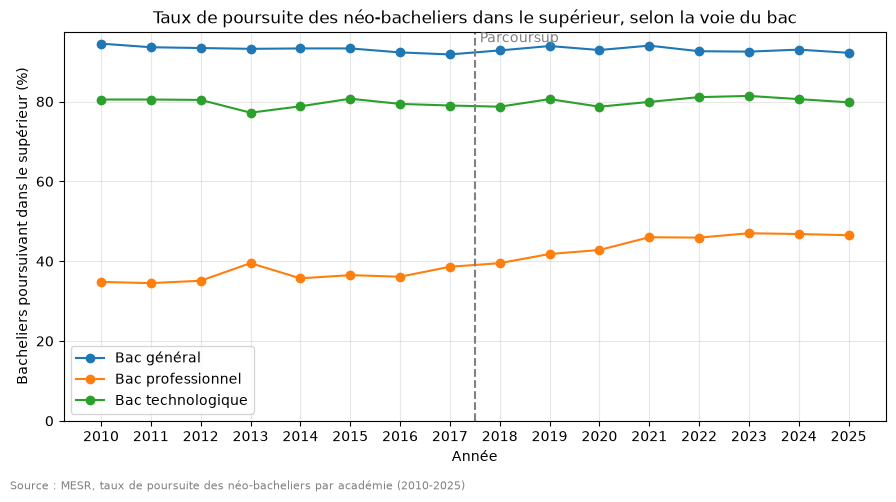

In [5]:
poursuite = preparer_poursuite(charger_poursuite())

# Taux de poursuite (en %) par année et par voie du bac : une colonne par voie
tableau_poursuite = taux_poursuite(poursuite, ["annee", "voie"]).unstack()

courbes(tableau_poursuite,
        titre="Taux de poursuite des néo-bacheliers dans le supérieur, selon la voie du bac",
        axe_y="Bacheliers poursuivant dans le supérieur (%)",
        source="MESR, taux de poursuite des néo-bacheliers par académie (2010-2025)",
        annee_reperee=2018, texte_repere="Parcoursup");

Le taux de poursuite des bacheliers professionnels passe de 34,8 % en 2010 à 38,6 % en 2017, puis à 46,5 % en 2025. Celui des bacheliers généraux (environ 93 %) et technologiques (environ 80 %) reste stable.

On relie ensuite ce fichier aux admis de Parcoursup, par académie et par année. On obtient un tableau avec une ligne par académie et par année : c'est la jointure entre les deux sources. Attention : Parcoursup donne l'académie de la formation, et le fichier de poursuite l'académie du bac.

In [6]:
panel = panel_academies(base, poursuite)

print(panel.shape, "-", panel["academie"].nunique(), "académies")
panel.head()

(240, 13) - 30 académies


,academie,annee,acc_tot,acc_neobac,acc_bp,acc_bt,acc_brs,bacheliers_Bac général,bacheliers_Bac professionnel,bacheliers_Bac technologique,poursuivants_Bac général,poursuivants_Bac professionnel,poursuivants_Bac technologique
0,Aix-Marseille,2018,24485,18607,2068,3850,4363,15646,7291,6172,14346.33570,2568.58960,4569.22180
1,Aix-Marseille,2019,27080,19253,2287,4081,4614,15268,7063,6176,14116.18750,2891.03480,4783.35260
2,Aix-Marseille,2020,28793,21222,2484,4331,6454,17001,7636,6767,15693.57670,3437.52100,4947.35940
3,Aix-Marseille,2021,27614,19604,2143,3542,5888,16450,7179,5887,15659.18680,3515.97980,4461.22740
4,Aix-Marseille,2022,26776,18561,1911,3455,5708,16159,6812,5649,15171.71334,3293.76365,4450.19656


## 3. Bacheliers professionnels et technologiques en BTS et en IUT

Deux règles visent à ouvrir les filières courtes : des places réservées aux bacheliers professionnels en BTS, et, depuis la création du BUT en 2021, un objectif d'environ la moitié de bacheliers technologiques en IUT. On suit la part de ces bacheliers parmi les néo-bacheliers admis.

,Bacs professionnels admis en BTS,Bacs technologiques admis en IUT
session,,
2018,41.2,33.8
2019,40.2,34.2
2020,40.0,34.5
2021,43.1,42.4
2022,43.7,44.0
2023,42.3,43.4
2024,43.0,45.2
2025,44.7,45.5


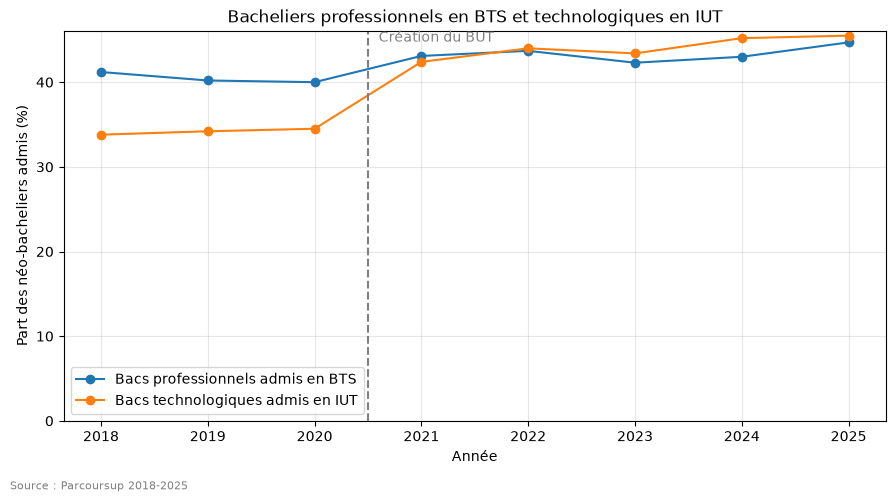

In [7]:
# Deux séries : les bacs pro admis en BTS, les bacs techno admis en IUT (en % des néo-bacheliers admis)
bacs = pd.DataFrame({
    "Bacs professionnels admis en BTS": part_bac_admis(base, "BTS", "acc_bp"),
    "Bacs technologiques admis en IUT": part_bac_admis(base, "IUT", "acc_bt"),
})

courbes(bacs,
        titre="Bacheliers professionnels en BTS et technologiques en IUT",
        axe_y="Part des néo-bacheliers admis (%)",
        source="Parcoursup 2018-2025",
        annee_reperee=2021, texte_repere="Création du BUT");
bacs

La part de bacheliers technologiques parmi les admis en IUT fait un saut en 2021, de 34,5 % à 42,4 %, l'année de la création du BUT, puis atteint 45,5 % en 2025 : l'objectif fixé aux IUT se voit directement dans les données. En BTS, la part de bacheliers professionnels progresse plus lentement, de 41,2 % en 2018 à 44,7 % en 2025.

On utilise ensuite le tableau par académie, issu de la jointure entre Parcoursup et le fichier de poursuite d'études. Pour chaque académie, on compare la part des bacheliers professionnels parmi tous les bacheliers de l'académie, et leur part parmi les néo-bacheliers admis dans les formations de l'académie. Si les bacheliers professionnels étaient admis autant que les autres, les points seraient sur la diagonale.

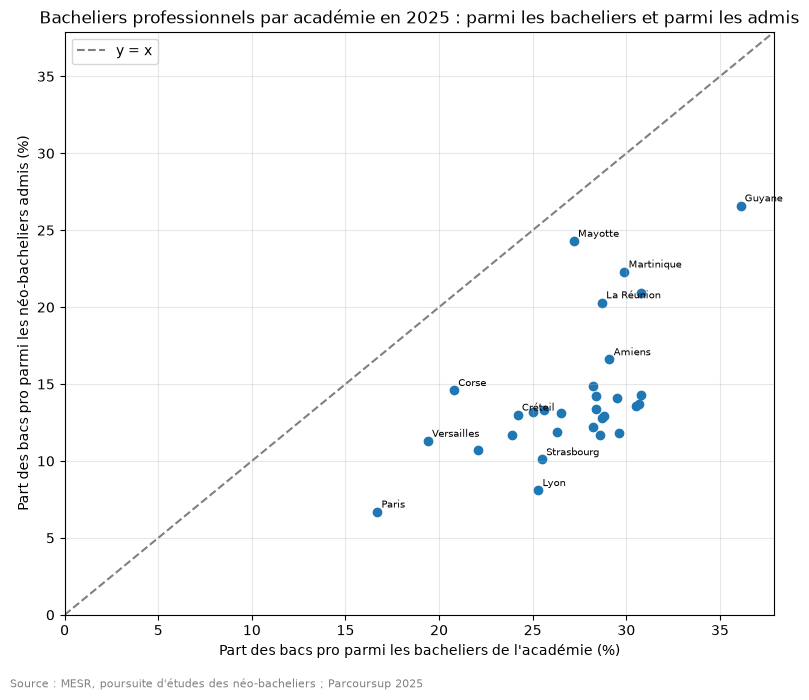

In [8]:
bac_pro = bac_pro_bacheliers_et_admis(panel, 2025)

nuage(bac_pro, x="part_bacheliers", y="part_admis", etiquette="academie",
      titre="Bacheliers professionnels par académie en 2025 : parmi les bacheliers et parmi les admis",
      axe_x="Part des bacs pro parmi les bacheliers de l'académie (%)",
      axe_y="Part des bacs pro parmi les néo-bacheliers admis (%)",
      source="MESR, poursuite d'études des néo-bacheliers ; Parcoursup 2025",
      a_nommer=["Paris", "Versailles", "Créteil", "Lyon", "Strasbourg", "Corse", "Amiens",
                "Guyane", "Mayotte", "Martinique", "La Réunion"]);

Toutes les académies sont sous la diagonale : les bacheliers professionnels sont environ deux fois moins présents parmi les admis de Parcoursup que parmi les bacheliers (par exemple, à Paris, 16,7 % des bacheliers mais 6,7 % des admis). Ce rapport est le même en 2018 et en 2025 (0,51 puis 0,52 en moyenne). Une partie de l'écart vient de ce que beaucoup de bacheliers professionnels ne demandent pas d'études supérieures, ou les suivent hors Parcoursup (apprentissage) : ce graphique décrit les admis, pas les refus.

## 4. Zoom Île-de-France : le secteur unique de 2019

Depuis la session 2019, les académies de Paris, Créteil et Versailles forment un seul secteur dans Parcoursup. On regarde l'effet de ce changement dans les deux sources :
- Parcoursup : la part des admis venant de l'académie de Paris, dans les formations parisiennes ;
- poursuite d'études : la part des bacheliers franciliens qui poursuivent dans une autre académie d'Île-de-France.

,"Admis de l'académie de Paris, dans les formations parisiennes",Bacheliers franciliens poursuivant dans une autre académie d'IDF
2016,NaN,31.1
2017,NaN,30.6
2018,25.1,31.6
2019,20.8,35.2
2020,19.9,36.1
2021,18.9,37.6
2022,17.8,37.9
2023,18.0,37.8
2024,17.7,37.9
2025,16.4,38.0


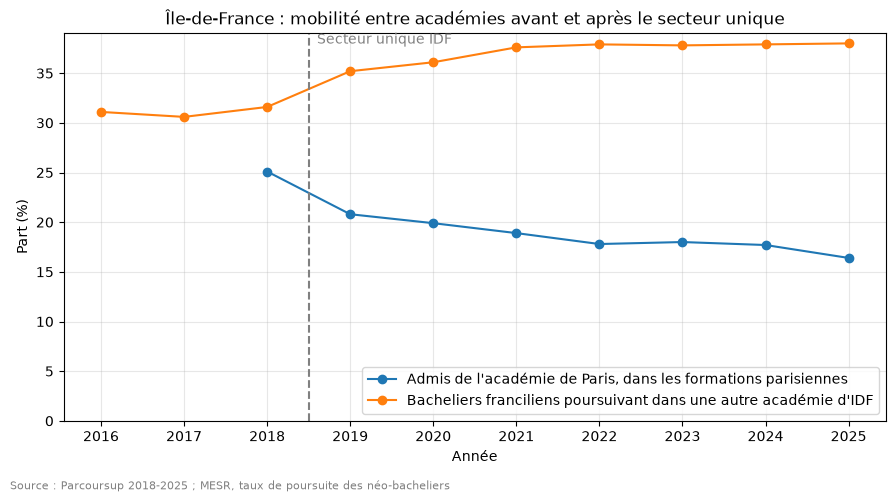

In [9]:
# Les deux indicateurs côte à côte, en %, de 2016 à 2025 (Parcoursup commence en 2018)
idf = pd.DataFrame({
    "Admis de l'académie de Paris, dans les formations parisiennes": part_admis_meme_academie(base, "Paris"),
    "Bacheliers franciliens poursuivant dans une autre académie d'IDF": part_poursuite_autre_academie_idf(poursuite),
}).loc[2016:]

courbes(idf,
        titre="Île-de-France : mobilité entre académies avant et après le secteur unique",
        axe_y="Part (%)",
        source="Parcoursup 2018-2025 ; MESR, taux de poursuite des néo-bacheliers",
        annee_reperee=2019, texte_repere="Secteur unique IDF");
idf

Les deux sources montrent la même rupture en 2019. Dans les formations parisiennes, la part des admis venant de l'académie de Paris passe de 25,1 % en 2018 à 20,8 % en 2019, puis à 16,4 % en 2025. Parmi les bacheliers franciliens qui poursuivent dans le supérieur, la part de ceux qui étudient dans une autre académie d'Île-de-France reste entre 30 et 32 % jusqu'en 2018, puis passe à 35,2 % en 2019 et à 38 % en 2025. Les formations parisiennes accueillent donc davantage de bacheliers de Créteil et de Versailles. Ces données ne disent pas si ces nouveaux admis viennent de milieux moins favorisés.

## 5. Formations sélectives et non sélectives : la place des boursiers

La sélection est l'étape où Parcoursup peut favoriser ou freiner la démocratisation : ce sont les formations sélectives qui choisissent leurs admis. On les compare aux formations non sélectives (surtout les licences), qui accueillent une grande partie des boursiers et des bacheliers professionnels.

Les formations sélectives représentent 79 % des formations de la base.

In [10]:
formations_selectives = base_selective(base)

print(len(formations_selectives), "formations sélectives sur", len(base))

81919 formations sélectives sur 104274


Pour mesurer la place des boursiers, on ne compare pas la part de boursiers d'une année à l'autre : le nombre de boursiers recensés fait un saut en 2020 et chute en 2025, aussi bien parmi les vœux que parmi les admis. Ces sauts viennent des critères d'attribution de bourses, pas de la sélection.

On compare donc, la même année, la part de boursiers parmi les vœux des néo-bacheliers et parmi les néo-bacheliers admis. Le rapport des deux vaut 1 si les boursiers sont aussi présents parmi les admis que parmi les vœux ; au-dessus de 1, ils sont plus présents parmi les admis.

selective,Formations non sélectives,Formations sélectives
session,,
2018,1.16,1.18
2019,1.15,1.04
2020,1.23,1.04
2021,1.22,1.07
2022,1.19,1.06
2023,1.18,1.10
2024,1.18,1.11
2025,1.15,1.06


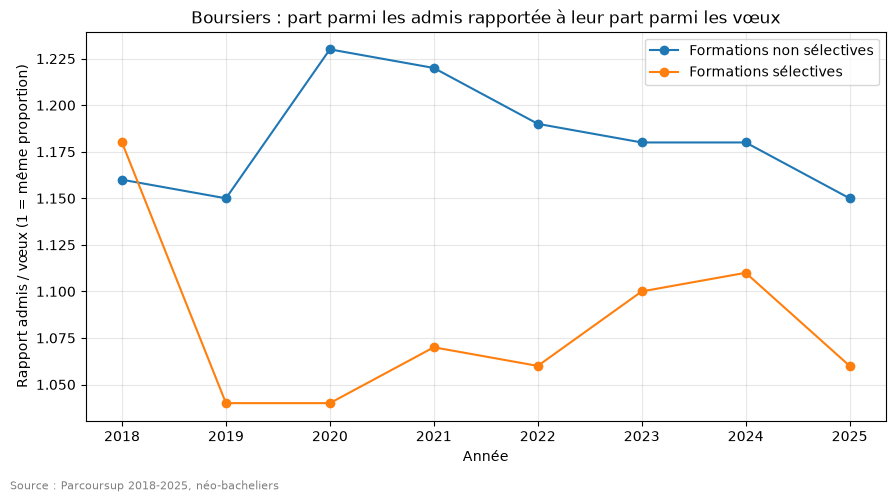

In [11]:
boursiers = boursiers_admis_et_candidats(base, ["session", "selective"])

# Rapport admis / vœux : une colonne pour les non sélectives (0) et une pour les sélectives (1)
rapport_boursiers = boursiers["rapport"].unstack().rename(columns={0.0: "Formations non sélectives",
                                                                   1.0: "Formations sélectives"})

courbes(rapport_boursiers,
        titre="Boursiers : part parmi les admis rapportée à leur part parmi les vœux",
        axe_y="Rapport admis / vœux (1 = même proportion)",
        source="Parcoursup 2018-2025, néo-bacheliers",
        depuis_zero=False);
rapport_boursiers

Chaque année, le rapport est supérieur à 1 : les boursiers sont un peu plus présents parmi les admis que parmi les vœux. L'écart est plus faible dans les formations sélectives (entre 1,04 et 1,11 depuis 2019) que dans les non sélectives (entre 1,15 et 1,23). Il ne s'élargit pas depuis 2019. En 2018, la sélectivité est reportée depuis 2020 : la valeur de cette année est à lire avec prudence.

Limites : ce sont des vœux et non des candidats (un candidat fait plusieurs vœux), et un rapport supérieur à 1 peut aussi venir des choix des candidats (vœux plus nombreux chez les non-boursiers, par exemple). On regarde ensuite le détail par filière parmi les formations sélectives.

In [12]:
# Même rapport parmi les formations sélectives, pour les principales filières
principales = formations_selectives[formations_selectives["filiere"].isin(["CPGE", "BTS", "IUT"])]
boursiers_admis_et_candidats(principales, ["session", "filiere"])["rapport"].unstack()

filiere,BTS,CPGE,IUT
session,,,
2018,1.00,1.13,0.99
2019,1.00,1.21,1.05
2020,1.00,1.10,1.05
2021,1.01,1.13,1.09
2022,0.99,1.14,1.08
2023,1.01,1.14,1.07
2024,1.00,1.11,1.05
2025,0.97,1.12,0.99


En BTS, le rapport reste proche de 1 chaque année : les boursiers sont admis dans la même proportion que leur part dans les vœux. En CPGE, il est plus élevé (entre 1,10 et 1,21) : parmi les néo-bacheliers admis en CPGE, les boursiers sont un peu plus présents que parmi les vœux. Ce sont des descriptions : elles ne disent pas si cet écart vient de la sélection des formations (par exemple des quotas de boursiers) ou des choix des candidats.

## Le milieu social des lycées qui accueillent les CPGE et les BTS

On classe les formations installées dans un lycée en quatre groupes de même taille selon l'IPS du lycée, des moins favorisés aux plus favorisés, puis on calcule la part de boursiers parmi les néo-bacheliers admis. Comme le nombre de boursiers recensés change en 2020 et en 2025, on compare les groupes entre eux la même année, plutôt que les niveaux d'une année à l'autre.

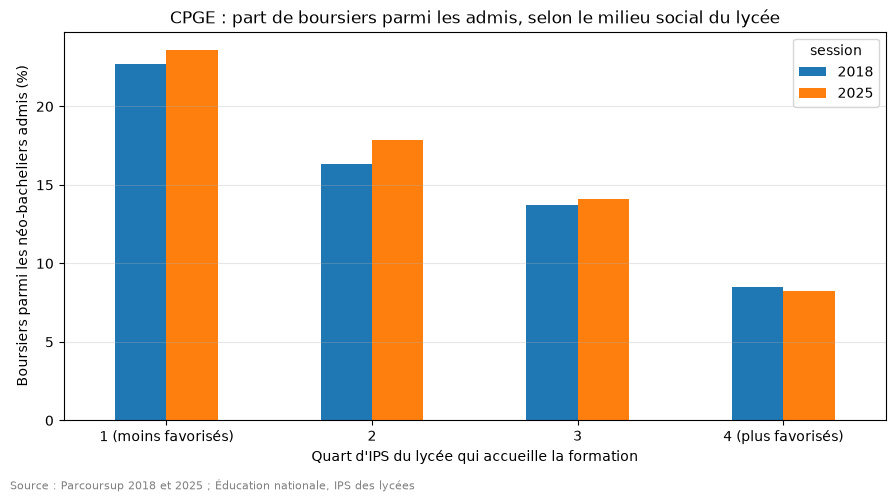

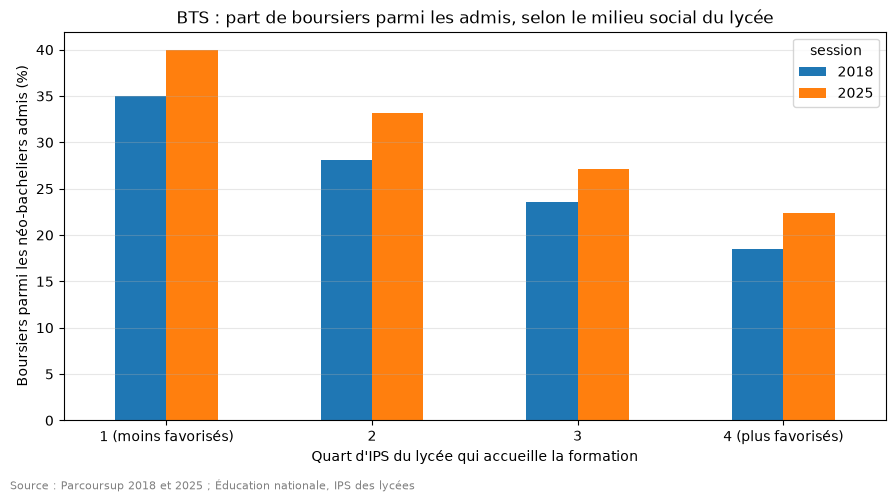

In [13]:
base = ajouter_tranche_ips(base)

for filiere in ["CPGE", "BTS"]:
    formations = base[base["filiere"] == filiere]
    # Une ligne par quart d'IPS, une colonne par session : on garde 2018 et 2025
    part = boursiers_admis_et_candidats(formations, ["tranche_ips", "session"])["part_admis"].unstack()
    part.index.name = "Quart d'IPS du lycée qui accueille la formation"
    barres(part[[2018, 2025]],
           titre=f"{filiere} : part de boursiers parmi les admis, selon le milieu social du lycée",
           axe_y="Boursiers parmi les néo-bacheliers admis (%)",
           source="Parcoursup 2018 et 2025 ; Éducation nationale, IPS des lycées")

L'écart selon le milieu social du lycée est net, et il est le même en 2018 et en 2025. En CPGE, les boursiers représentent 23 à 24 % des admis dans les lycées les moins favorisés, contre 8 % dans les plus favorisés. En BTS, ils représentent 35 % contre 18 % en 2018, et 40 % contre 22 % en 2025. En BTS, les barres de 2025 sont un peu plus hautes pour tous les groupes à la fois : cela vient du comptage des boursiers, qui change d'une année à l'autre (voir plus haut), et non d'un rapprochement entre les groupes.

Autrement dit, sur cette période, Parcoursup n'a pas rapproché la composition sociale des CPGE et des BTS selon le lycée qui les accueille. Limite : l'IPS décrit les élèves du lycée (en seconde, première et terminale), pas ceux de la CPGE ou du BTS eux-mêmes.

## Etude de l'évolution de la mixité dans les formations sélectives

Un autre critère permettant d'observer l'ouverture de l'enseignement supérieur à l'ensemble de la population est la mixité. En effet, depuis de nombreuses années, le système éducatif français cherche à rétablir la mixité dans toutes les formmations (on pense en particulier aux formations sélectives scientifiques). 

Nous allons donc regarder comment à évoluer ce critère depuis 2018.

Attention : on commence en 2019. En 2018, la part de filles parmi les vœux (41 % dans les formations sélectives, 46 % dans l'ensemble) est très inférieure à celle des années suivantes (55 % en 2019) : la colonne voe_tot_f ne semble pas comptée de la même façon cette année-là. Ce sont aussi des vœux et non des candidates (une candidate fait plusieurs vœux).

In [14]:
# Parts de filles (en %) parmi les vœux et parmi les admis, à partir de 2019 (2018 n'est pas comparable)
part_voeux = part_filles_globale(formations_selectives, "voe_tot_f", "voe_tot") * 100
part_admis = part_filles_globale(formations_selectives, "acc_tot_f", "acc_tot") * 100

comparaison = pd.DataFrame({
    "Part de filles parmi les vœux": part_voeux,
    "Part de filles parmi les admises et admis": part_admis,
}).loc[2019:]
comparaison["Écart (admis - vœux, en points)"] = (
    comparaison["Part de filles parmi les admises et admis"]
    - comparaison["Part de filles parmi les vœux"]
)
comparaison.round(1)

,Part de filles parmi les vœux,Part de filles parmi les admises et admis,"Écart (admis - vœux, en points)"
session,,,
2019,55.0,51.0,-4.0
2020,54.4,51.0,-3.3
2021,54.1,50.3,-3.8
2022,53.3,50.3,-2.9
2023,52.1,50.5,-1.6
2024,52.2,50.7,-1.5
2025,52.3,50.7,-1.6


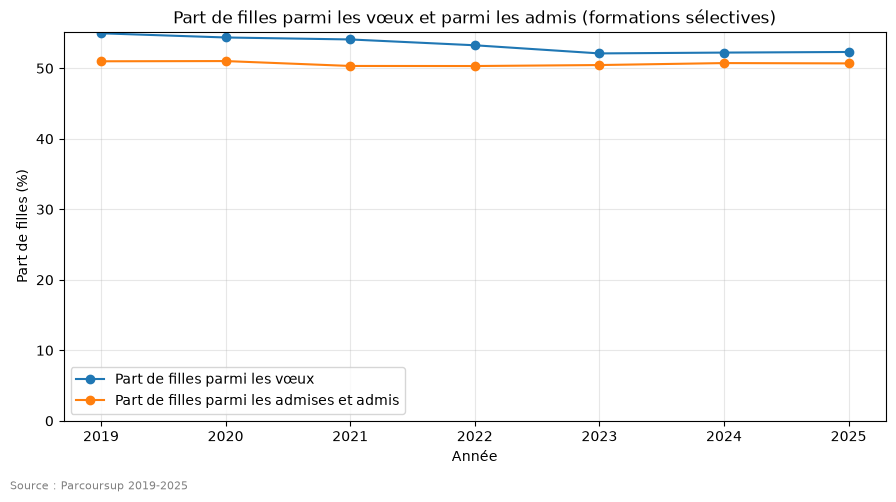

In [15]:
# Même fonction que les autres courbes du rapport : axe à partir de 0, une graduation par année
courbes(comparaison.iloc[:, :2],
        titre="Part de filles parmi les vœux et parmi les admis (formations sélectives)",
        axe_y="Part de filles (%)",
        source="Parcoursup 2019-2025");

*commentaire d'Aurélien sur ce graphique*

## Etude de l'accès aux formations sélectives du supérieur selon la mention obtenue au bac

Nous allons maintenant nous interesser à la répartition des mention au bac dans l'enseignement supérieur. 

La limite de ce critère est que les formations selectives doivent par définition sélectionner leurs élèves sur des critères scolaires. Ainsi il paraitrait cohérent que les élèves ayant des mentions plus faibles soient désaventagés dans l'accès à certaines formations de haut niveau.

*champ : nous avons remarqué qu'il y avait un écart négatif entre la somme des mentions et le total des admis. Ainsi nous savons que les élèves ne sont comptés qu'une fois dans le total des mentions. Cependant les colonnes de mentions ne concernent en général que les néo-bacheliers (bac de l'année), alors que acc_tot inclut aussi les anciens bacheliers, les candidats en réorientation, les bacs étrangers, etc. Ces admis n'ont pas de mention dans ces colonnes. C'est pour cela que l'écart est négatif. 
Nous allons donc faire le ratio des mentions une à une sur la somme total des élèves neo-bacheliers.*

In [16]:
mentions = ["acc_sansmention", "acc_ab", "acc_b", "acc_tb", "acc_tbf", "acc_mention_nonrenseignee"]
parts = parts_mentions(base, mentions, "acc_neobac")
parts

acc_sansmention    acc_ab     acc_b    acc_tb   acc_tbf  \
selective session                                                            
0.0       2018            0.481180  0.275031  0.156715  0.079615  0.000000   
          2019            0.492091  0.269536  0.151631  0.072459  0.000000   
          2020            0.360410  0.321061  0.206948  0.104599  0.000000   
          2021            0.297689  0.366353  0.239995  0.081075  0.008221   
          2022            0.338392  0.338744  0.229898  0.083829  0.008151   
          2023            0.351169  0.331575  0.223441  0.083225  0.008745   
          2024            0.328215  0.339306  0.237141  0.086611  0.007641   
          2025            0.320625  0.340840  0.241147  0.087195  0.008841   
1.0       2018            0.328651  0.316869  0.208660  0.136827  0.000000   
          2019            0.343879  0.316947  0.207821  0.121973  0.000000   
          2020            0.209160  0.334006  0.274865  0.179188  0.000000   
          2021            0.214373  0.363863  0.274611  0.124325  0.019645   
          2022            0.254451  0.329512  0.258867  0.134580  0.021320   
          2023            0.280070  0.316064  0.246606  0.133907  0.021489   
          2024            0.277785  0.324519  0.251847  0.126221  0.018624   
          2025            0.280031  0.328525  0.247066  0.123479  0.019640   

                   acc_mention_nonrenseignee  
selective session                             
0.0       2018                      0.007458  
          2019                      0.014283  
          2020                      0.006982  
          2021                      0.006667  
          2022                      0.000035  
          2023                      0.001845  
          2024                      0.001085  
          2025                      0.001352  
1.0       2018                      0.008994  
          2019                      0.009380  
          2020                      0.002777  
          2021                      0.003183  
          2022                      0.000260  
          2023                      0.001863  
          2024                      0.001003  
          2025                      0.001259

Nous avons juste montré le phénomène global de diminution d'élèves sans mention au bac!  
On va donc utiliser les chiffres sur les mentions au bac parmis les présents aux sessions et le nombre d''admis à chaque sessions. Ces chiffres osnt présents sur les notes d'informations publiées chaque années par la DEPP suite au bac.   
Avec ces chiffres montrant l'inflation de mention au cours du temps, nous allons pourvoir corriger ce biais inflationiste dans nos chiffres sur le supérieur.

**Part des élèves avec mentions au bac entre 2018 et 2025 (en % des admis)**

In [17]:
# ajout manuel des chiffres de 2018-2019-2020 (% des présents, source : DEPP)
# Données DEPP : répartition des présents par mention (%)
# et effectifs totaux de présents et d'admis


donnees = pd.DataFrame(
    {
    "presents": [767614, 759111, 760833, 735245,
                 733104, 743874, 753147, 744412],

    "admis": [677287, 668343, 722971, 689021,
              666840, 674941, 686952, 682001],

    "acc_sansmention": [40.6, 41.1, 32.5, 29.7,
                        32.3, 33.9, 33.0, 33.1],

    "acc_ab": [26.0, 25.8, 31.5, 34.1,
               30.3, 29.1, 30.0, 30.2],

    "acc_b": [14.1, 14.1, 20.3, 21.3,
              19.4, 18.7, 19.5, 19.6],

    # Très bien + félicitations du jury à partir de 2021
    "acc_tb": [7.5, 7.1, 10.7, 8.7,
               9.0, 9.0, 8.7, 8.8]
    },
        index=pd.Index([2018, 2019, 2020,2021,2022,2023,2024,2025], name="session")
        )


df_bacheliers = pd.DataFrame(donnees)

# Correction du biais lié aux candidats non admis
facteur = df_bacheliers["presents"] / df_bacheliers["admis"]

colonnes_mentions = [
    "acc_sansmention",
    "acc_ab",
    "acc_b",
    "acc_tb"
]

for col in colonnes_mentions:
    df_bacheliers[col] = df_bacheliers[col] * facteur

# Tableau final
#df_bacheliers = df_bacheliers[
#    ["session"] + colonnes_mentions]

df_bacheliers[colonnes_mentions] = (
    df_bacheliers[colonnes_mentions].round(2)
)

print(df_bacheliers)



         presents   admis  acc_sansmention  acc_ab  acc_b  acc_tb
session                                                          
2018       767614  677287            46.01   29.47  15.98    8.50
2019       759111  668343            46.68   29.30  16.01    8.06
2020       760833  722971            34.20   33.15  21.36   11.26
2021       735245  689021            31.69   36.39  22.73    9.28
2022       733104  666840            35.51   33.31  21.33    9.89
2023       743874  674941            37.36   32.07  20.61    9.92
2024       753147  686952            36.18   32.89  21.38    9.54
2025       744412  682001            36.13   32.96  21.39    9.61


**correction du biais inflationniste sur les mentions**  
Nous créons un indice : part de la mention dans le supérieur / part de la mention au bac (même année)

Un indice de 1 signifie que le supérieur recrute le même profil que l'ensemble des bacheliers. Au-dessus de 1, la mention est sur-représentée, et si l'indice monte, le supérieur recrute plus de bonnes mentions que ce que l'inflation seule explique. Et inversement, pour les indice en dessous de 1.

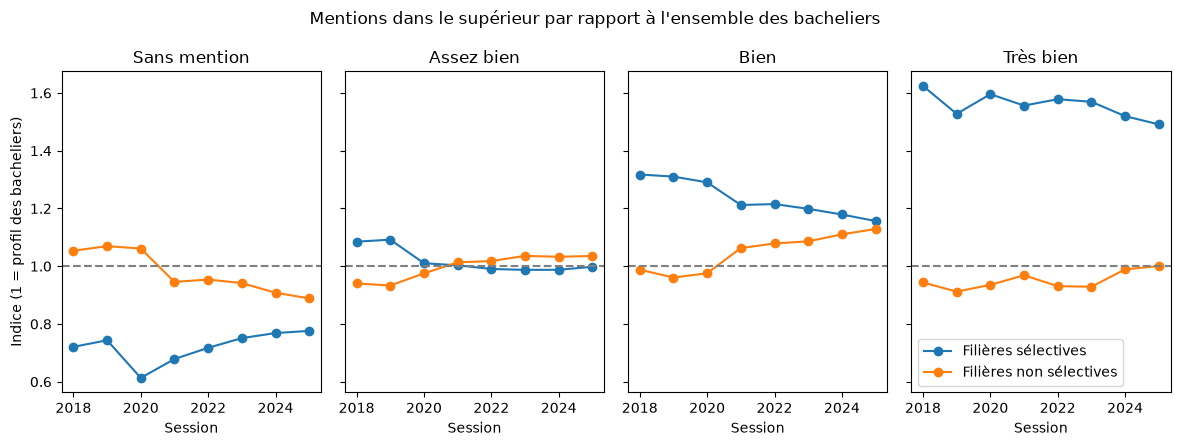

In [18]:
from sources.indicateurs import indice_mentions
from sources.graphiques import graphique_indice_mentions

indice = indice_mentions(base, df_bacheliers)
fig = graphique_indice_mentions(
    indice,
    mentions=("acc_sansmention", "acc_ab", "acc_b", "acc_tb"),
)

La correction de l'inflation des mentions au baccalauréat permet de dépasser la simple augmentation du niveau scolaire des bacheliers pour observer l'évolution réelle des profils recrutés dans l'enseignement supérieur.

Dans les filières sélectives, les bacheliers sans mention restent nettement sous-représentés : leur indice est de 0,72 en 2018, descend à 0,61 en 2020, puis remonte à 0,78 en 2025. À l'inverse, les titulaires d'une mention bien ou très bien y demeurent surreprésentés. La surreprésentation des mentions bien diminue lentement (de 1,32 en 2018 à 1,16 en 2025), tandis que celle des mentions très bien reste particulièrement élevée sur toute la période (de 1,62 en 2018 à 1,49 en 2025). Ces résultats montrent que les filières sélectives continuent de concentrer les meilleurs profils scolaires, malgré une légère atténuation des écarts.

Dans les filières non sélectives, les indices restent proches de 1 : la répartition des mentions y est proche de celle de l'ensemble des bacheliers. Les bacheliers sans mention, légèrement surreprésentés jusqu'en 2020 (indice de 1,05 à 1,07), deviennent sous-représentés à partir de 2021, avec un indice de 0,89 en 2025. Parallèlement, les mentions bien passent de 0,99 à 1,13, et les mentions très bien de 0,94 à 1,00.

Finalement, les filières sélectives continuent de privilégier les meilleurs dossiers, tandis que les filières non sélectives accueillent des profils plus proches de l'ensemble des bacheliers, mais avec une évolution défavorable aux bacheliers sans mention.

Note : la colonne des félicitations du jury (acc_tbf) n'existe qu'à partir de 2021 ; avant, les félicitations sont comprises dans les mentions très bien. Les données de référence sur les mentions au bac viennent des notes d'information de la DEPP.

## Etude de l'évolution de l'origine géographique des élèves de l'enseignement supérieur

*cf. carte codée par Aurélien*